# Market-maker latency experiment

Change the settings below, then run all cells. The experiment varies one naive market maker’s latency while keeping its other parameters fixed. Each latency uses the same combinations of decision and population seeds. These defaults are a small pilot.

In [10]:
from pathlib import Path
import sys
import json
import math
from pprint import pprint
import matplotlib.pyplot as plt

# Works when launched from the project root or a folder inside it.
project_root = next(
    path for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "simulation.py").is_file()
)
sys.path.insert(0, str(project_root))

from experiments.basic_experiments import ExperimentTrader, IndependentVariableScope

## Background traders

20 random traders, 5 naive market makers, and 5 inventory-aware market makers. Empty `trader_cfg` dictionaries use the defaults in `factory.py`. The factory currently spells its minimum price-offset field `min_max_price_offest`.

In [11]:
background_config = {'random_trader': {'quantity': 20,
                   'trader_cfg': {},
                   'strategy_cfg': {'min_buy_prob': 0.2,
                                    'max_buy_prob': 0.6,
                                    'min_sell_prob': 0.2,
                                    'max_sell_prob': 0.6,
                                    'min_cancel_prob': 0.01,
                                    'max_cancel_prob': 0.1,
                                    'min_limit_prob': 0.5,
                                    'max_limit_prob': 1.0,
                                    'min_max_quantity': 1,
                                    'max_max_quantity': 5,
                                    'min_max_price_offest': 0,
                                    'max_max_price_offset': 3,
                                    'reference_price': 100}},
 'naive_mm': {'quantity': 5,
              'trader_cfg': {},
              'strategy_cfg': {'min_half_spread': 1,
                               'max_half_spread': 2,
                               'min_time_req': 1,
                               'max_time_req': 5,
                               'min_tolerance': 0,
                               'max_tolerance': 2,
                               'min_quantity': 1,
                               'max_quantity': 5}},
 'inventory_aware_mm': {'quantity': 5,
                        'trader_cfg': {},
                        'strategy_cfg': {'min_half_spread': 1,
                                         'max_half_spread': 2,
                                         'min_time_req': 1,
                                         'max_time_req': 5,
                                         'min_tolerance': 0,
                                         'max_tolerance': 2,
                                         'min_quantity': 1,
                                         'max_quantity': 5,
                                         'min_target_ratio': 0.4,
                                         'max_target_ratio': 0.6,
                                         'min_ratio_error': 0.05,
                                         'max_ratio_error': 0.1}}}

sim_config = json.dumps(background_config)

In [12]:
background_config = {'random_trader': {'quantity': 20,
                   'trader_cfg': {'min_latency': 5,
                                  'max_latency': 5,
                                  'min_latency_dev': 0,
                                  'max_latency_dev': 0},
                   'strategy_cfg': {'min_buy_prob': 0.2, 
                                    'max_buy_prob': 0.6,
                                    'min_sell_prob': 0.2,
                                    'max_sell_prob': 0.6,
                                    'min_cancel_prob': 0.01,
                                    'max_cancel_prob': 0.1,
                                    'min_limit_prob': 0.5,
                                    'max_limit_prob': 1.0,
                                    'min_max_quantity': 1,
                                    'max_max_quantity': 5,
                                    'min_max_price_offest': 0,
                                    'max_max_price_offset': 3,
                                    'reference_price': 100}},
 'naive_mm': {'quantity': 5,
              'trader_cfg': {'min_latency': 5,
                             'max_latency': 5,
                             'min_latency_dev': 0,
                             'max_latency_dev': 0},
              'strategy_cfg': {'min_half_spread': 1,
                               'max_half_spread': 2,
                               'min_time_req': 1,
                               'max_time_req': 5,
                               'min_tolerance': 0,
                               'max_tolerance': 2,
                               'min_quantity': 1,
                               'max_quantity': 5}},
 'inventory_aware_mm': {'quantity': 5,
                        'trader_cfg': {'min_latency': 5,
                                       'max_latency': 5,
                                       'min_latency_dev': 0,
                                       'max_latency_dev': 0},
                        'strategy_cfg': {'min_half_spread': 1,
                                         'max_half_spread': 2,
                                         'min_time_req': 1,
                                         'max_time_req': 5,
                                         'min_tolerance': 0,
                                         'max_tolerance': 2,
                                         'min_quantity': 1,
                                         'max_quantity': 5,
                                         'min_target_ratio': 0.4,
                                         'max_target_ratio': 0.6,
                                         'min_ratio_error': 0.05,
                                         'max_ratio_error': 0.1}}}

sim_config = json.dumps(background_config)

In [13]:
background_config = {'random_trader': {'quantity': 20,
                   'trader_cfg': {'min_latency': 5,
                                  'max_latency': 5,
                                  'min_latency_dev': 0,
                                  'max_latency_dev': 0},
                   'strategy_cfg': {'min_buy_prob': 0.2, 
                                    'max_buy_prob': 0.6,
                                    'min_sell_prob': 0.2,
                                    'max_sell_prob': 0.6,
                                    'min_cancel_prob': 0.01,
                                    'max_cancel_prob': 0.3,
                                    'min_limit_prob': 0.5,
                                    'max_limit_prob': 1.0,
                                    'min_max_quantity': 1,
                                    'max_max_quantity': 5,
                                    'min_max_price_offest': 0,
                                    'max_max_price_offset': 3,
                                    'reference_price': 100}},
 }

sim_config = json.dumps(background_config)

## Target trader and run settings

The target is an additional trader with ID 0. Its `latency=None` placeholder is replaced by each sweep value. To vary a strategy parameter instead, use `IndependentVariableScope.STRATEGY` and its field name.

In [14]:
target_parameters = {
    "strategy_name": "naive_mm",
    "trader_cfg": {
        "initial_cash": 10000,
        "initial_position": 100,
        "latency": None,
        "latency_deviation": 0,
    },
    "strategy_cfg": {
        "half_spread": 2,
        "time_req": 5,
        "tolerance": 1,
        "quantity": 3,
    },
}

latencies = range(21)
decision_seeds = range(10)
trader_parameter_seeds = range(10)
sim_steps = 1000

experiment = ExperimentTrader(
    ind_var="latency",
    ind_var_values=latencies,
    target_trader_parameters=target_parameters,
    sim_config=sim_config,
    decision_seeds=decision_seeds,
    trader_parameter_seeds=trader_parameter_seeds,
    sim_steps=sim_steps,
    ind_var_scope=IndependentVariableScope.TRADER,
)
print(f"{len(latencies) * len(decision_seeds) * len(trader_parameter_seeds)} simulations × {sim_steps:,} steps")

2100 simulations × 1,000 steps


In [15]:
results = experiment.run_experiment(verbose=True)
#pprint(results, sort_dicts=False)
pprint({
    latency: metrics["excess_pnl"]
    for latency, metrics in results.items()
}, sort_dicts=False)

Experiment 10% complete
Experiment 20% complete
Experiment 30% complete
Experiment 40% complete
Experiment 50% complete
Experiment 60% complete
Experiment 70% complete
Experiment 80% complete
Experiment 90% complete
Experiment 100% complete
{0: {'count': 100, 'mean': 54.052776032090186, 'variance': 10552.818021411009},
 1: {'count': 100, 'mean': 53.52721353530884, 'variance': 9142.549132187836},
 2: {'count': 100, 'mean': 52.61190490722656, 'variance': 7493.039691201844},
 3: {'count': 100, 'mean': 57.84450897216797, 'variance': 8624.790653963177},
 4: {'count': 100, 'mean': 49.386484375, 'variance': 8273.661583673676},
 5: {'count': 100, 'mean': 40.84479835510254, 'variance': 8684.296734106201},
 6: {'count': 100, 'mean': 49.96373413085937, 'variance': 6954.160438059886},
 7: {'count': 100, 'mean': 41.638125, 'variance': 7371.771219741359},
 8: {'count': 100, 'mean': 41.69787841796875, 'variance': 6400.406087527967},
 9: {'count': 100, 'mean': 33.5432373046875, 'variance': 7207.117614

## Compare outcomes

Error bars show one sample standard deviation across seed combinations, **not confidence intervals**. P&L includes changes in inventory value. Sharpe is per simulation timestep, not annualised; undefined values are omitted by the runner. Latency also affects how frequently a trader can act in this model.

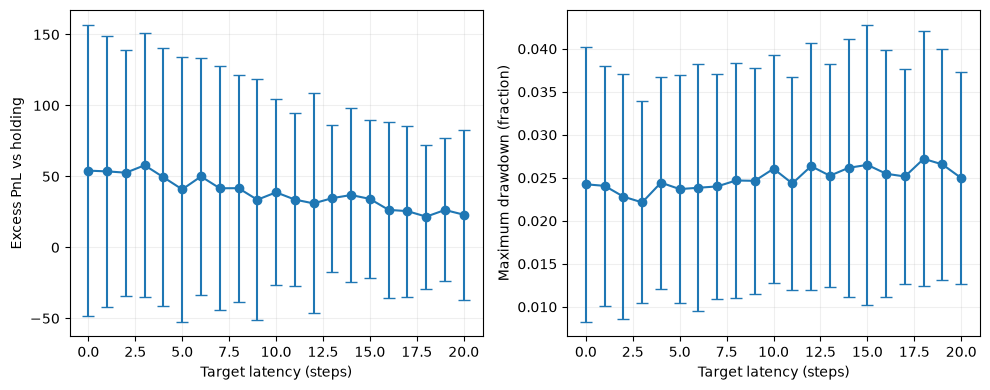

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, metric, label in zip(
    axes, ["excess_pnl", "drawdown"], ["Excess PnL vs holding", "Maximum drawdown (fraction)"]
):
    means = [results[value][metric]["mean"] for value in latencies]
    deviations = [
        math.sqrt(results[value][metric]["variance"])
        if results[value][metric]["variance"] is not None else float("nan")
        for value in latencies
    ]
    ax.errorbar(latencies, means, yerr=deviations, marker="o", capsize=4)
    ax.set(xlabel="Target latency (steps)", ylabel=label)
    ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()